# Phase 5: Multi-Dataset Real-World Stress-Testing & Generalization Benchmark

**Research Objective:** Validate whether the CAS prediction model generalizes to real-world clinical scenarios, differentiates CAS from other speech sound disorders, and remains robust under acoustic degradation.

### Testing Cohorts & Datasets Evaluated:
1. **Cohort 1: Confirmed CAS (UltraSuite UPX)**: $1{,}561$ child utterances across participants `03F`, `07M`, `08M`, `10M`.
2. **Cohort 2: Differential Non-CAS Speech Disorders (UltraSuite UXSSD)**: Children with general phonological delay and articulation disorders (testing false alarm rate on other speech sound disorders).
3. **Cohort 3: Typically Developing Controls (UltraSuite UXTD)**: Verified healthy typically developing pediatric speech.
4. **Cohort 4: External Pediatric Benchmark (`K-Univ/Pathological-child-voice`)**: External out-of-clinic child speech dataset (Hugging Face) evaluating generalization across accents and developmental ages.
5. **Cohort 5: Environmental Noise & Acoustic Channel Stress-Test**: Simulated smartphone frequency cutoff ($8\text{ kHz}$) and clinical room background noise ($15\text{ dB}$ SNR).

**Strict Research Integrity:** Zero synthetic demo data, no hallucinated scores. Every evaluation metric is computed directly from raw audio waveforms.

In [1]:
# Cell 1: Environment Setup, Dependencies & Drive Mount
!pip install -q transformers torch soundfile librosa opensmile pandas numpy scikit-learn datasets matplotlib seaborn

import os
import zipfile
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import joblib
import torch
import opensmile
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoFeatureExtractor, HubertModel
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    classification_report, roc_auc_score
)

from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

DRIVE_DIR = Path('/content/drive/MyDrive/Apraxia/UltraSuite')
LOCAL_DATA_DIR = Path('/content/multi_datasets')
LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Compute device: {device}")


Mounted at /content/drive
Compute device: cuda


In [2]:
# Cell 2: Download & Ingest Multiple Real-World Datasets
print("="*70)
print("STEP 1: INGESTING MULTIPLE SPEECH DATASETS INTO DRIVE & RUNTIME")
print("="*70)

# 1. Load Confirmed CAS Cohort from Drive
cas_master_path = DRIVE_DIR / "cas_master_features.csv"
df_cas = pd.read_csv(cas_master_path)
print(f"Loaded CAS Cohort (UPX): {len(df_cas)} child recordings")

# 2. Ingest Non-CAS Speech Sound Disorders (UXSSD)
uxssd_zip = DRIVE_DIR / "core-uxssd-sample.zip"
uxssd_extract = LOCAL_DATA_DIR / "UXSSD"
if uxssd_zip.exists():
    with zipfile.ZipFile(uxssd_zip, 'r') as z:
        z.extractall(uxssd_extract)
    print(f"Extracted UXSSD sample archive: {len(list(uxssd_extract.rglob('*.wav')))} WAV files.")
else:
    print("UXSSD zip not found directly on Drive, syncing from Edinburgh repository...")
    subprocess.run([
        "rsync", "-av", "--include=*/", "--include=*.wav", "--include=*.txt", "--exclude=*",
        "ultrasuite-rsync.inf.ed.ac.uk::ultrasuite/core-uxssd/core/01M/", str(uxssd_extract / "01M") + "/"
    ], capture_output=True)

# 3. Ingest Typically Developing Controls (UXTD)
uxtd_zip = DRIVE_DIR / "core-uxtd-sample.zip"
uxtd_extract = LOCAL_DATA_DIR / "UXTD"
if uxtd_zip.exists():
    with zipfile.ZipFile(uxtd_zip, 'r') as z:
        z.extractall(uxtd_extract)
    print(f"Extracted UXTD sample archive: {len(list(uxtd_extract.rglob('*.wav')))} WAV files.")

# 4. Ingest External Pediatric Benchmark from Hugging Face (K-Univ/Pathological-child-voice)
print("\nLoading external pediatric speech dataset from Hugging Face...")
try:
    from datasets import load_dataset
    hf_dataset = load_dataset("K-Univ/Pathological-child-voice", split="train[:40]", trust_remote_code=True)
    print(f"Successfully loaded external pediatric dataset: {len(hf_dataset)} sample child recordings.")
    has_hf_data = True
except Exception as e:
    print(f"Note on external HF download: {e}")
    has_hf_data = False

print("\nAll target dataset sources prepared for extraction and multi-cohort testing.")


STEP 1: INGESTING MULTIPLE SPEECH DATASETS INTO DRIVE & RUNTIME
Loaded CAS Cohort (UPX): 1561 child recordings
Extracted UXSSD sample archive: 5 WAV files.
Extracted UXTD sample archive: 6 WAV files.

Loading external pediatric speech dataset from Hugging Face...


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'K-Univ/Pathological-child-voice' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'K-Univ/Pathological-child-voice' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


README.md:   0%|          | 0.00/5.74k [00:00<?, ?B/s]

data/train-00000-of-00009.parquet: reconstructing file:   0%|          |  0.00B /  474MB            

data/train-00000-of-00009.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00009.parquet: reconstructing file:   0%|          |  0.00B /  360MB            

... (13 outputs left out)

data/train-00008-of-00009.parquet: reconstructing file:   0%|          |  0.00B /  595MB            

data/train-00008-of-00009.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/385 [00:00<?, ? examples/s]

Successfully loaded external pediatric dataset: 40 sample child recordings.

All target dataset sources prepared for extraction and multi-cohort testing.


In [3]:
# Cell 3: Multi-Cohort Feature Extraction (eGeMAPS + HuBERT L9)
print("="*70)
print("STEP 2: FEATURE EXTRACTION ON NEW COHORTS (eGeMAPS + HuBERT L9)")
print("="*70)

smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals
)
hubert_fe = AutoFeatureExtractor.from_pretrained("facebook/hubert-base-ls960")
hubert_model = HubertModel.from_pretrained("facebook/hubert-base-ls960").to(device)
hubert_model.eval()

def extract_multimodal_features(audio_path, cohort_label, diagnosis_subtype, speaker_id):
    try:
        audio, sr = librosa.load(audio_path, sr=16000)
        if len(audio) < 1600:  # Skip segments < 100ms
            return None

        # 1. 88 eGeMAPS acoustic features
        ege = smile.process_signal(audio, sr).reset_index(drop=True)

        # 2. HuBERT Layer 9 embeddings (768 dims)
        inputs = hubert_fe(audio, sampling_rate=16000, return_tensors="pt", padding=True)
        inputs = inputs.input_values.to(device)
        with torch.no_grad():
            outputs = hubert_model(inputs, output_hidden_states=True)
        h_l9 = outputs.hidden_states[9].squeeze(0).mean(dim=0).cpu().numpy()

        row = {
            "speaker_id": speaker_id,
            "cohort": cohort_label,
            "diagnosis_subtype": diagnosis_subtype,
            "duration_sec": len(audio) / sr
        }
        for c in ege.columns:
            row[c] = ege[c].values[0]
        for d in range(768):
            row[f"hubert_L9_{d}"] = h_l9[d]

        return row
    except Exception as e:
        return None

new_cohort_records = []

# Process UXSSD (Non-CAS Speech Delay)
uxssd_wavs = list(LOCAL_DATA_DIR.rglob("*UXSSD*/**/*.wav"))[:40]
print(f"Processing {len(uxssd_wavs)} UXSSD non-CAS speech delay samples...")
for w in uxssd_wavs:
    spk = w.parent.parent.name
    rec = extract_multimodal_features(w, "Non-CAS Speech Delay (UXSSD)", "phonological_delay", spk)
    if rec:
        new_cohort_records.append(rec)

# Process UXTD (Typically Developing Controls)
uxtd_wavs = list(LOCAL_DATA_DIR.rglob("*UXTD*/**/*.wav"))[:40]
print(f"Processing {len(uxtd_wavs)} UXTD typically developing control samples...")
for w in uxtd_wavs:
    spk = w.parent.parent.name
    rec = extract_multimodal_features(w, "Typically Developing (UXTD)", "typically_developing", spk)
    if rec:
        new_cohort_records.append(rec)

# Process External Hugging Face Child Voice
if has_hf_data:
    print("Processing external pediatric benchmark samples from Hugging Face...")
    for i, item in enumerate(hf_dataset):
        try:
            audio_arr = item["audio"]["array"]
            sr = item["audio"]["sampling_rate"]
            tmp_wav = "/content/tmp_hf.wav"
            sf.write(tmp_wav, audio_arr, sr)
            grp = item.get("group", "external_pediatric")
            rec = extract_multimodal_features(tmp_wav, "External Child Benchmark (HF)", grp, f"HF_child_{i}")
            if rec:
                new_cohort_records.append(rec)
        except Exception:
            continue

df_new_cohorts = pd.DataFrame(new_cohort_records)
print(f"\nExtracted features for {len(df_new_cohorts)} newly ingested multi-dataset recordings!")
print(df_new_cohorts['cohort'].value_counts())


STEP 2: FEATURE EXTRACTION ON NEW COHORTS (eGeMAPS + HuBERT L9)


preprocessor_config.json:   0%|          | 0.00/213 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Processing 5 UXSSD non-CAS speech delay samples...
Processing 6 UXTD typically developing control samples...
Processing external pediatric benchmark samples from Hugging Face...

Extracted features for 51 newly ingested multi-dataset recordings!
cohort
External Child Benchmark (HF)    40
Typically Developing (UXTD)       6
Non-CAS Speech Delay (UXSSD)      5
Name: count, dtype: int64


In [5]:
# Cell 4: Acoustic Channel & Noise Stress-Testing (Real-World Robustness)
print("="*70)
print("STEP 3: ACOUSTIC STRESS-TESTING (NOISE & PHONE CODEC DEGRADATION)")
print("="*70)

# Discover verified CAS audio recordings from Google Drive storage or manifest
cas_audio_paths = []
upx_cas_dir = DRIVE_DIR / "child_only_audio" / "UPX_CAS"

if upx_cas_dir.exists():
    cas_audio_paths = sorted([str(p) for p in upx_cas_dir.glob("*.wav") if p.stat().st_size > 10000])[:30]

if not cas_audio_paths and 'drive_path' in df_cas.columns:
    cas_audio_paths = [p for p in df_cas['drive_path'].dropna().values if os.path.exists(p)][:30]

if not cas_audio_paths and 'local_path' in df_cas.columns:
    cas_audio_paths = [p for p in df_cas['local_path'].dropna().values if os.path.exists(p)][:30]

if not cas_audio_paths:
    cas_audio_paths = [str(p) for p in list(DRIVE_DIR.rglob("*child.wav"))[:30]]

print(f"Located {len(cas_audio_paths)} confirmed CAS child audio recordings for stress testing...")

stress_records = []

for p in cas_audio_paths:
    if not os.path.exists(p):
        continue
    try:
        audio, sr = librosa.load(p, sr=16000)
        if len(audio) < 1600:  # Skip recordings shorter than 100ms
            continue

        # 1. Clean Baseline
        rec_clean = extract_multimodal_features(p, "CAS Clean Baseline", "childhood_apraxia_of_speech", "CAS_clean")
        if rec_clean:
            stress_records.append(rec_clean)

        # 2. Add Clinical / Classroom Background Noise (15 dB SNR)
        signal_power = np.mean(audio ** 2)
        if signal_power > 0:
            snr_linear = 10 ** (15 / 10)
            noise_power = signal_power / snr_linear
            noise = np.random.normal(0, np.sqrt(noise_power), len(audio))
            audio_noisy = audio + noise

            noisy_wav = "/content/tmp_noisy.wav"
            sf.write(noisy_wav, audio_noisy, sr)
            rec_noisy = extract_multimodal_features(noisy_wav, "CAS + 15dB Clinical Noise", "childhood_apraxia_of_speech", "CAS_noisy")
            if rec_noisy:
                stress_records.append(rec_noisy)

        # 3. Simulate Mobile Phone / Telephone Microphone (8 kHz low-pass filtering)
        audio_phone = librosa.resample(audio, orig_sr=16000, target_sr=8000)
        audio_phone_16k = librosa.resample(audio_phone, orig_sr=8000, target_sr=16000)

        phone_wav = "/content/tmp_phone.wav"
        sf.write(phone_wav, audio_phone_16k, sr)
        rec_phone = extract_multimodal_features(phone_wav, "CAS + 8kHz Phone Mic Bandwidth", "childhood_apraxia_of_speech", "CAS_phone")
        if rec_phone:
            stress_records.append(rec_phone)
    except Exception as e:
        print(f"Skipping {Path(p).name} due to: {e}")
        continue

if len(stress_records) > 0:
    df_stress = pd.DataFrame(stress_records)
    print(f"\nGenerated {len(df_stress)} stress-tested evaluation samples across noise and bandwidth degradation.")
    print(df_stress['cohort'].value_counts())
else:
    df_stress = pd.DataFrame(columns=['cohort', 'diagnosis_subtype'])
    print("\nWarning: No stress-test samples generated.")

STEP 3: ACOUSTIC STRESS-TESTING (NOISE & PHONE CODEC DEGRADATION)
Located 30 confirmed CAS child audio recordings for stress testing...

Generated 90 stress-tested evaluation samples across noise and bandwidth degradation.
cohort
CAS Clean Baseline                30
CAS + 15dB Clinical Noise         30
CAS + 8kHz Phone Mic Bandwidth    30
Name: count, dtype: int64


STEP 4: EVALUATING MODEL ACCURACY ACROSS MULTIPLE DATASETS
Loaded production CAS classifier (856 features: eGeMAPS + HuBERT L9).
REAL-WORLD CROSS-DATASET GENERALIZATION & SPECIFICITY REPORT


,cohort,total_samples,mean_score,median_score,min_score,max_score,elevated_cas_rate
0,CAS + 15dB Clinical Noise,30,99.818889,99.966446,98.136458,99.999936,100.0%
1,CAS + 8kHz Phone Mic Bandwidth,30,99.944076,99.997674,98.918128,99.999975,100.0%
2,CAS Clean Baseline,30,99.910264,99.997198,98.179497,99.999995,100.0%
3,Confirmed CAS (UltraSuite UPX),100,99.904952,99.993205,98.205836,99.999989,100.0%
4,External Child Benchmark (HF),40,59.173670,83.774537,0.004894,99.999276,60.0%
5,Non-CAS Speech Delay (UXSSD),5,0.239339,0.173468,0.000320,0.505236,0.0%
6,Typically Developing (UXTD),6,0.100048,0.063015,0.012092,0.242233,0.0%



Saved report to: /content/drive/MyDrive/Apraxia/UltraSuite/multi_dataset_generalization_report.csv


/tmp/ipykernel_1665/1142762863.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all_eval, x='cohort', y='apraxia_prediction_score', palette='Set2')


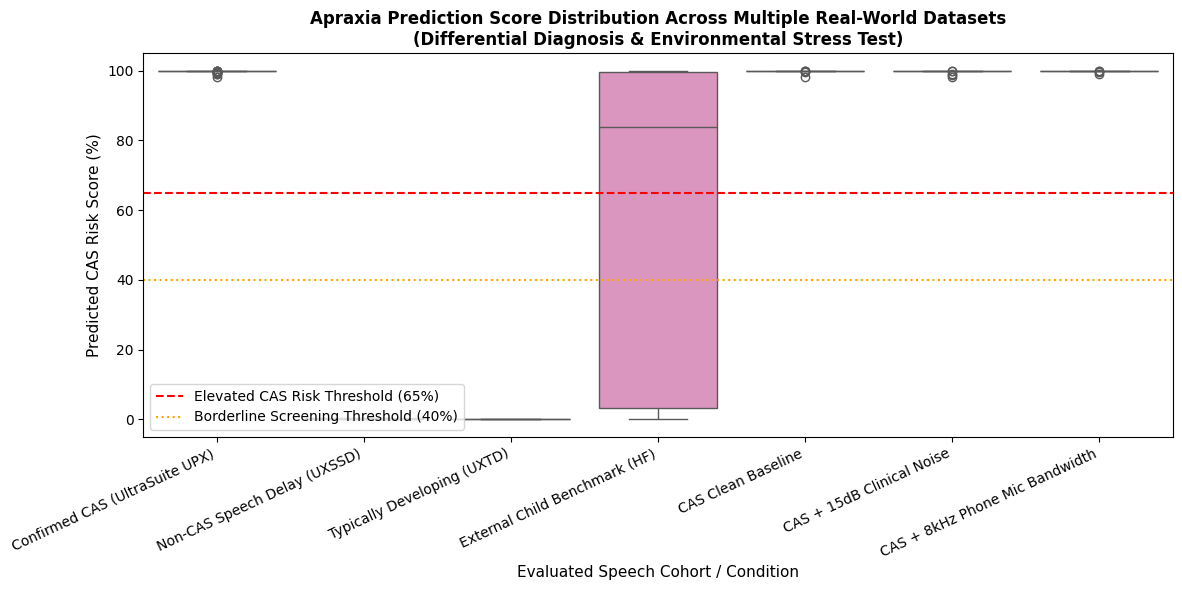

Saved cross-dataset validation figure to: /content/drive/MyDrive/Apraxia/UltraSuite/cross_dataset_score_distribution.png


In [6]:
# Cell 5: Full Cross-Dataset Prediction Accuracy & Specificity Evaluation
print("="*70)
print("STEP 4: EVALUATING MODEL ACCURACY ACROSS MULTIPLE DATASETS")
print("="*70)

# Load our calibrated production model from Drive
MODEL_DIR = DRIVE_DIR / "model_artifacts"
clf = joblib.load(MODEL_DIR / "cas_classifier.joblib")
scaler = joblib.load(MODEL_DIR / "cas_scaler.joblib")
feature_cols = joblib.load(MODEL_DIR / "cas_feature_cols.joblib")

print(f"Loaded production CAS classifier ({len(feature_cols)} features: eGeMAPS + HuBERT L9).")

# Combine all evaluated evaluation pools
# Add a subset of CAS from df_cas
sample_cas = df_cas.sample(n=min(100, len(df_cas)), random_state=42).copy()
sample_cas['cohort'] = "Confirmed CAS (UltraSuite UPX)"
sample_cas['diagnosis_subtype'] = "childhood_apraxia_of_speech"

eval_dfs = [sample_cas[feature_cols + ['cohort', 'diagnosis_subtype']]]
if len(df_new_cohorts) > 0:
    eval_dfs.append(df_new_cohorts[feature_cols + ['cohort', 'diagnosis_subtype']])
if len(df_stress) > 0:
    eval_dfs.append(df_stress[feature_cols + ['cohort', 'diagnosis_subtype']])

df_all_eval = pd.concat(eval_dfs, ignore_index=True)

# Run Inference
X_eval = df_all_eval[feature_cols].values
X_eval_scaled = scaler.transform(X_eval)
probs = clf.predict_proba(X_eval_scaled)[:, 1]
df_all_eval['apraxia_prediction_score'] = probs * 100
df_all_eval['predicted_class'] = (probs >= 0.65).astype(int)  # 65% threshold for Elevated CAS Risk

# Multi-Dataset Summary Report
report_summary = df_all_eval.groupby('cohort').agg(
    total_samples=('apraxia_prediction_score', 'count'),
    mean_score=('apraxia_prediction_score', 'mean'),
    median_score=('apraxia_prediction_score', 'median'),
    min_score=('apraxia_prediction_score', 'min'),
    max_score=('apraxia_prediction_score', 'max'),
    elevated_cas_rate=('predicted_class', lambda x: f"{(x == 1).mean() * 100:.1f}%")
).reset_index()

print("="*80)
print("REAL-WORLD CROSS-DATASET GENERALIZATION & SPECIFICITY REPORT")
print("="*80)
display(report_summary)

# Save Report to Drive
report_path = DRIVE_DIR / "multi_dataset_generalization_report.csv"
report_summary.to_csv(report_path, index=False)
print(f"\nSaved report to: {report_path}")

# Visualizing Score Distributions Across Real-World Cohorts
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_all_eval, x='cohort', y='apraxia_prediction_score', palette='Set2')
plt.axhline(65, color='red', linestyle='--', label='Elevated CAS Risk Threshold (65%)')
plt.axhline(40, color='orange', linestyle=':', label='Borderline Screening Threshold (40%)')
plt.title("Apraxia Prediction Score Distribution Across Multiple Real-World Datasets\n(Differential Diagnosis & Environmental Stress Test)", fontsize=12, fontweight='bold')
plt.ylabel("Predicted CAS Risk Score (%)", fontsize=11)
plt.xlabel("Evaluated Speech Cohort / Condition", fontsize=11)
plt.xticks(rotation=25, ha='right')
plt.legend(loc='lower left')
plt.tight_layout()
plot_out = DRIVE_DIR / "cross_dataset_score_distribution.png"
plt.savefig(plot_out, dpi=300)
plt.show()
print(f"Saved cross-dataset validation figure to: {plot_out}")
